# 08b — EDA phần B: KHI NÀO (người phụ trách: Bengaluru/Amritsar)

**Câu hỏi nghiên cứu chung**

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**


**Quy ước chung** (chi tiết ở `08_eda.ipynb`): so sánh giữa thành phố chỉ dùng `win` (khoảng chung); "nặng" = AQI >= 201 trên số ngày **có AQI**;
mùa: Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11); chỉ viết "có liên quan", **không** viết "gây ra".
Hàm dùng chung nằm ở `src/eda_utils.py` (không sửa nếu chưa báo nhóm).

**Làm việc nhóm:** chỉ sửa notebook **này** và chỉ lưu hình có tên của phần mình (`eda_<số>_...png`). `git pull` trước khi push.

## Việc cần làm
1. **Biểu đồ 2**: heatmap thành phố x tháng (AQI trung vị, thang màu tuần tự, ghi số trên ô) để thấy mùa cao điểm.
2. **Biểu đồ 3**: xu hướng theo năm **trong từng thành phố**, chỉ tháng 1-6 (cùng kỳ) để năm 2020 so được với các năm trước.
3. Chẩn đoán: liệt kê confounder cho mỗi phát hiện (mùa, xu hướng dài hạn, lockdown 2020, thay đổi trạm đo và độ phủ dữ liệu).

## Cẩn thận (đã phát hiện khi kiểm tra)
- Chuỗi các thành phố dài ngắn khác nhau và có vài ô **thưa dữ liệu**: ví dụ Jaipur tháng 1-6/2017 chỉ có 11 ngày có AQI, Gurugram 2016 chỉ 95 ngày. Hãy **luôn xem bảng số ngày `n_tbl`** cạnh bảng trung bình trước khi kết luận về xu hướng, và bỏ hoặc ghi chú các ô có ít ngày.
- Năm 2020 chỉ đến 01/07 và có lockdown: chỉ nêu "có liên quan", không kết luận nguyên nhân. Mùa, xu hướng giảm dần qua các năm và lockdown đều là confounder của việc "2020 thấp hơn 2019".
- Heatmap dùng `win` (khoảng chung) vì cần so các thành phố; biểu đồ xu hướng dùng `eda` nhưng **trong từng thành phố riêng**.

## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)

## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


## B0. Bảng xu hướng tháng 1-6, kèm số ngày để biết ô nào thưa

In [2]:
h1 = eda[eda.month <= 6].dropna(subset=["AQI"])
trend_tbl = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="mean", observed=True).round(0)
n_tbl     = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="size", observed=True)
print("AQI trung bình, tháng 1-6:");  display(trend_tbl)
print("Số ngày có AQI trong ô đó (ô nhỏ = kết luận yếu):"); display(n_tbl)

AQI trung bình, tháng 1-6:


year,2015,2016,2017,2018,2019,2020
City,,,,,,
Delhi,306.0,298.0,294.0,263.0,246.0,182.0
Gurugram,NaN,239.0,319.0,250.0,211.0,159.0
Lucknow,133.0,257.0,260.0,257.0,224.0,158.0
Jaipur,NaN,NaN,83.0,165.0,132.0,105.0
Bengaluru,111.0,114.0,89.0,86.0,108.0,80.0
Amritsar,NaN,NaN,92.0,148.0,104.0,93.0
Chennai,178.0,138.0,109.0,105.0,109.0,80.0
Hyderabad,135.0,127.0,128.0,105.0,104.0,78.0


Số ngày có AQI trong ô đó (ô nhỏ = kết luận yếu):


year,2015,2016,2017,2018,2019,2020
City,,,,,,
Delhi,181.0,182.0,180.0,181.0,181.0,182.0
Gurugram,NaN,95.0,161.0,163.0,180.0,182.0
Lucknow,98.0,160.0,178.0,181.0,181.0,182.0
Jaipur,NaN,NaN,11.0,180.0,181.0,182.0
Bengaluru,102.0,180.0,181.0,177.0,181.0,182.0
Amritsar,NaN,NaN,111.0,156.0,179.0,173.0
Chennai,95.0,169.0,178.0,181.0,181.0,182.0
Hyderabad,86.0,179.0,180.0,181.0,181.0,182.0


## B1. Biểu đồ 2: heatmap thành phố x tháng

Mỗi ô thành phố x tháng có 75-107 ngày (khoảng 3 mùa của cùng một tháng).


month,1,2,3,4,5,6,7,8,9,10,11,12
City,,,,,,,,,,,,
Delhi,340.0,284.0,191.0,198.0,196.0,152.0,100.0,98.0,106.0,274.0,360.0,376.0
Lucknow,344.0,266.0,207.0,154.0,173.0,142.0,84.0,84.0,85.0,249.0,352.0,345.0
Gurugram,308.0,210.0,154.0,150.0,166.0,174.0,109.0,81.0,92.0,280.0,332.0,316.0
Jaipur,138.0,130.0,110.0,125.0,138.0,108.0,88.0,82.0,91.0,150.0,190.0,147.0
Amritsar,111.0,123.0,92.0,93.0,102.0,103.0,81.0,66.0,80.0,138.0,209.0,140.0
Hyderabad,132.0,111.0,101.0,90.0,101.0,60.0,54.0,56.0,62.0,102.0,129.0,138.0
Chennai,116.0,89.0,86.0,68.0,80.0,96.0,85.0,82.0,93.0,84.0,86.0,92.0
Bengaluru,102.0,94.0,100.0,84.0,82.0,63.0,64.0,63.0,70.0,82.0,83.0,91.0


Đã lưu reports/figures/eda_02_heatmap_city_month.png


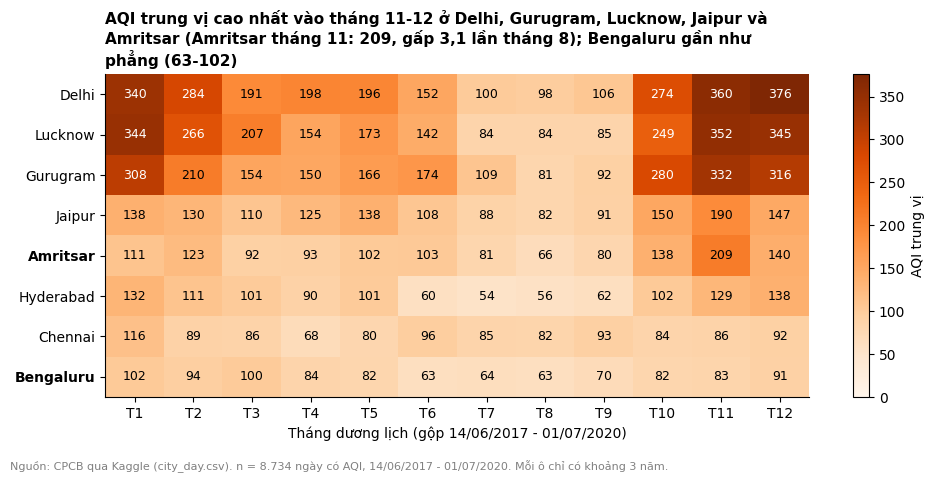

Amritsar: ngày AQI >= 201 = 117 | tháng 10-12: 89 (76%)
Bengaluru: ngày AQI >= 201 = 2 | trung vị tháng: min 63.0 max 102.0 (đỉnh/đáy 1,6 lần)


In [3]:
d = win.dropna(subset=["AQI"])
med = d.pivot_table(index="City", columns="month", values="AQI", aggfunc="median", observed=True)
n_m = d.pivot_table(index="City", columns="month", values="AQI", aggfunc="size", observed=True)
med = med.loc[d.groupby("City", observed=True).AQI.median().sort_values(ascending=False).index]   # cùng thứ tự với 08a
print(f"Mỗi ô thành phố x tháng có {n_m.min().min()}-{n_m.max().max()} ngày (khoảng 3 mùa của cùng một tháng).")
display(med.round(0))

fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(med.values, cmap="Oranges", vmin=0, aspect="auto")        # thang tuần tự, bắt đầu từ 0
ax.set_xticks(range(12)); ax.set_xticklabels([f"T{m}" for m in range(1, 13)])
ax.set_yticks(range(len(med))); ax.set_yticklabels(med.index.astype(str))
for lab in ax.get_yticklabels():
    if lab.get_text() in ("Bengaluru", "Amritsar"):
        lab.set_fontweight("bold")                                       # nhấn 2 thành phố của phần B
for i in range(med.shape[0]):
    for j in range(12):
        v = med.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * med.values.max() else "black")
cb = fig.colorbar(im, ax=ax); cb.set_label("AQI trung vị")
ax.set_xlabel("Tháng dương lịch (gộp 14/06/2017 - 01/07/2020)"); ax.set_ylabel("")

am, bl = med.loc["Amritsar"], med.loc["Bengaluru"]
finish_chart(fig, ax,
    f"AQI trung vị cao nhất vào tháng 11-12 ở Delhi, Gurugram, Lucknow, Jaipur và Amritsar (Amritsar tháng 11: {vn(am[11])}, "
    f"gấp {vn(am[11] / am[8], 1)} lần tháng 8); Bengaluru gần như phẳng ({vn(bl.min())}-{vn(bl.max())})", win,
    note="Mỗi ô chỉ có khoảng 3 năm.")
save_fig(fig, "02_heatmap_city_month")
plt.show()

# số liệu dùng trong bảng phát hiện B1
amd = d[(d.City == "Amritsar") & (d.AQI >= 201)]
print("Amritsar: ngày AQI >= 201 =", len(amd), "| tháng 10-12:", int(amd.month.isin([10, 11, 12]).sum()),
      f"({vn(amd.month.isin([10, 11, 12]).mean() * 100)}%)")
print("Bengaluru: ngày AQI >= 201 =", int((d[d.City == "Bengaluru"].AQI >= 201).sum()), "| trung vị tháng: min", bl.min(), "max", bl.max(),
      f"(đỉnh/đáy {vn(bl.max() / bl.min(), 1)} lần)")

## B2. Biểu đồ 3: xu hướng theo năm trong từng thành phố (tháng 1-6)

Ô bị bỏ khỏi hình (quá thưa): Gurugram 2016 (95 ngày); Lucknow 2015 (98 ngày); Jaipur 2017 (11 ngày); Bengaluru 2015 (102 ngày); Amritsar 2017 (111 ngày); Chennai 2015 (95 ngày); Hyderabad 2015 (86 ngày)


Đã lưu reports/figures/eda_03_trend_city_year.png


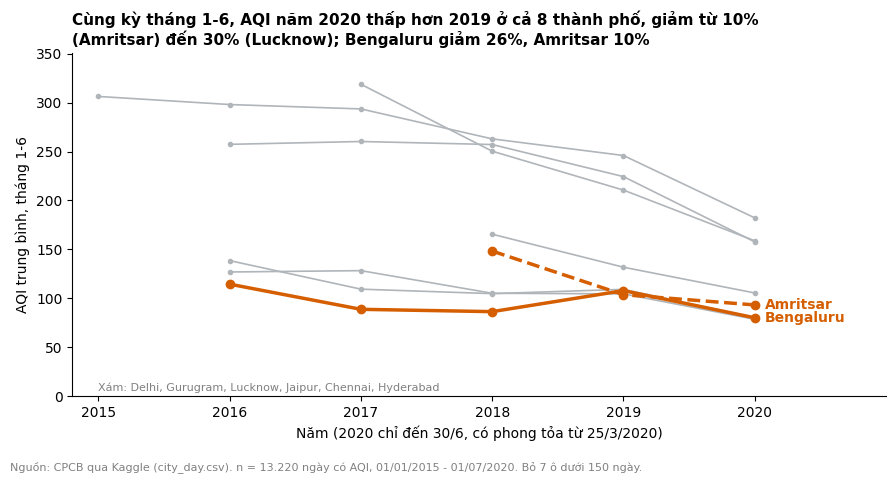

,"% đổi 2020 so với 2019, tháng 1-6"
City,
Delhi,-25.9
Gurugram,-24.6
Lucknow,-29.8
Jaipur,-20.0
Bengaluru,-25.8
Amritsar,-10.1
Chennai,-26.4
Hyderabad,-25.0


In [4]:
MIN_N = 150                                    # tháng 1-6 có khoảng 181 ngày; ô dưới 150 ngày bị bỏ khỏi hình (xem n_tbl ở B0)
trend_ok = trend_tbl_raw = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="mean", observed=True)
trend_ok = trend_tbl_raw.where(n_tbl >= MIN_N)
dropped = [f"{c} {int(y)} ({int(n_tbl.loc[c, y])} ngày)" for c in n_tbl.index for y in n_tbl.columns if n_tbl.loc[c, y] < MIN_N]
print("Ô bị bỏ khỏi hình (quá thưa):", "; ".join(dropped))

fig, ax = plt.subplots(figsize=(9, 4.8))
for c in trend_ok.index:
    s = trend_ok.loc[c].dropna()
    if c in ("Bengaluru", "Amritsar"):
        ax.plot(s.index, s.values, color=ACCENT, lw=2.5, marker="o", ls="-" if c == "Bengaluru" else "--", zorder=3)
        ax.text(s.index[-1] + 0.08, s.values[-1], c, color=ACCENT, fontsize=10, fontweight="bold", va="center")
    else:
        ax.plot(s.index, s.values, color=NEUTRAL, lw=1.2, marker="o", ms=3)
ax.text(2015.0, 5, "Xám: Delhi, Gurugram, Lucknow, Jaipur, Chennai, Hyderabad", fontsize=8, color="gray")
ax.set_xlim(2014.8, 2021.0); ax.set_ylim(0, trend_ok.max().max() * 1.1)
ax.set_xticks(range(2015, 2021)); ax.set_xlabel("Năm (2020 chỉ đến 30/6, có phong tỏa từ 25/3/2020)")
ax.set_ylabel("AQI trung bình, tháng 1-6")

chg = (trend_tbl_raw[2020] / trend_tbl_raw[2019] - 1) * 100             # 2020 so với 2019, cùng kỳ tháng 1-6
assert (chg < 0).all(), "có thành phố 2020 không thấp hơn 2019, phải sửa tiêu đề"
finish_chart(fig, ax,
    f"Cùng kỳ tháng 1-6, AQI năm 2020 thấp hơn 2019 ở cả {len(chg)} thành phố, giảm từ {vn(-chg.max())}% ({chg.idxmax()}) "
    f"đến {vn(-chg.min())}% ({chg.idxmin()}); Bengaluru giảm {vn(-chg['Bengaluru'])}%, Amritsar {vn(-chg['Amritsar'])}%", eda,
    note=f"Bỏ {len(dropped)} ô dưới {MIN_N} ngày.")
save_fig(fig, "03_trend_city_year")
plt.show()
display(chg.round(1).rename("% đổi 2020 so với 2019, tháng 1-6").to_frame())

### B3. Chẩn đoán: giảm của 2020 nằm trước hay sau phong tỏa (25/3/2020)?
Nếu chỉ do phong tỏa thì phần giảm phải xuất hiện **sau** 25/3. Tách tháng 1-6 thành hai đoạn cùng kỳ (1/1-24/3 và 25/3-30/6), so 2020 với 2019 trong **từng thành phố**. Chỉ là chẩn đoán, không kết luận nguyên nhân (mùa, thời tiết, xu hướng dài hạn vẫn là confounder).

In [5]:
def seg_mean(c, y, a, b):
    g = eda[(eda.City == c) & (eda.Date >= f"{y}-{a}") & (eda.Date <= f"{y}-{b}")].AQI.dropna()
    return g.mean(), len(g)

rows = []
for c in CITIES:
    r = {"City": c}
    for tag, (a, b) in {"truoc": ("01-01", "03-24"), "sau": ("03-25", "06-30")}.items():
        m19, n19 = seg_mean(c, 2019, a, b); m20, n20 = seg_mean(c, 2020, a, b)
        r[f"{tag}_2019"] = round(m19); r[f"{tag}_2020"] = round(m20)
        r[f"{tag}_doi_%"] = round((m20 / m19 - 1) * 100); r[f"{tag}_n_min"] = min(n19, n20)
    rows.append(r)
lock = pd.DataFrame(rows).set_index("City")
display(lock)

,truoc_2019,truoc_2020,truoc_doi_%,truoc_n_min,sau_2019,sau_2020,sau_doi_%,sau_n_min
City,,,,,,,,
Delhi,280,248,-11,83,217,126,-42,98
Gurugram,212,197,-7,83,209,126,-40,97
Lucknow,261,216,-17,83,193,107,-45,98
Jaipur,126,116,-7,83,136,96,-30,98
Bengaluru,114,96,-16,83,102,66,-36,98
Amritsar,93,108,16,81,112,80,-29,92
Chennai,120,81,-33,83,100,80,-20,98
Hyderabad,118,95,-19,83,93,64,-31,98


## Phát hiện của phần B (người ghép báo cáo sẽ gom bảng này vào mục 5)

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| B1 | Trong khoảng chung 14/06/2017 - 01/07/2020, Delhi, Gurugram, Lucknow, Jaipur và Amritsar có AQI trung vị cao nhất vào tháng 11-12 và thấp nhất vào tháng 7-9. Amritsar: trung vị tháng 11 là 209, gấp 3,1 lần tháng 8 (66); 89/117 ngày (76%) AQI >= 201 của Amritsar rơi vào tháng 10-12. Bengaluru gần như không có mùa: trung vị tháng chỉ dao động 63-102 (đỉnh/đáy 1,6 lần) và chỉ 2 ngày AQI >= 201. | 2 | Thời tiết (gió, mưa, lớp không khí sát mặt đất mỏng vào mùa đông) và nguồn phát thải theo mùa (ví dụ đốt rơm rạ sau mùa gặt ở vùng Punjab, lễ Diwali) có thể đi cùng đỉnh tháng 10-12; đây là giả thuyết, dữ liệu **không** có thời tiết hay nguồn phát thải để kiểm. | Mỗi ô thành phố x tháng chỉ có 75-107 ngày từ khoảng 3 mùa, nên một năm bất thường làm lệch trung vị. Amritsar thiếu 85 ngày AQI (7,6%). Trung vị che đợt ô nhiễm cực đoan. Chỉ có tương quan, không kết luận nguyên nhân. |
| B2 | Cùng kỳ tháng 1-6, AQI trung bình năm 2020 thấp hơn 2019 ở cả 8 thành phố (giảm 10% ở Amritsar đến 30% ở Lucknow). Bengaluru giảm 26% (108 xuống 80), Amritsar giảm 10% (104 xuống 93). Tách theo phong tỏa: Bengaluru giảm 16% trước 25/3 (114 xuống 96) và 36% sau (102 xuống 66); Amritsar tăng 16% trước 25/3 (93 lên 108) rồi giảm 29% sau (112 xuống 80). Bengaluru không giảm đều: 114 (2016), 89 (2017), 86 (2018), 108 (2019), 80 (2020). | 3 | Phong tỏa từ 25/3/2020; mùa (hai đoạn trước và sau 25/3 khác mùa nên so với cùng đoạn của 2019); xu hướng dài hạn (Bengaluru giảm trước phong tỏa nên không chỉ do phong tỏa); thời tiết; thay đổi trạm đo và độ phủ dữ liệu. | Chỉ so 2020 với 2019, mỗi đoạn 81-98 ngày. Amritsar chỉ có từ 27/02/2017 nên chỉ so được 2018-2020 (ô 2017 có 111 ngày, đã bỏ). 7 ô dưới 150 ngày bị bỏ khỏi hình (Bengaluru 2015 có 102 ngày). Năm 2020 chỉ đến 30/6. Chỉ viết là có liên quan, không kết luận nguyên nhân. |

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.